# Clase 5: Modelos No Supervisados Aplicados

**Machine Learning (RIA-805) — Octavo Ciclo — Robótica e Inteligencia Artificial**   
**Fecha:** Semana 3 — Bloque 1

**Objetivo:** Entrenar, comparar y visualizar modelos no supervisados (K-Means, DBSCAN, PCA, t-SNE) para descubrir patrones ocultos en datos sin etiquetas.

**Dataset:** Crop Recommendation — 2,200 muestras, 7 features, 22 cultivos.

**Conexión con la práctica:** En APE 7–8 van a hacer exactamente esto con Wall-Following. Si entienden este notebook, pueden hacer la práctica sin problemas.

## Recordatorio: ¿Qué vimos en 704?

En Inteligencia Artificial (704) ya vieron:

- **K-Means:** agrupa por proximidad a centroides. Requiere definir `k`.
- **DBSCAN:** agrupa por densidad. Puede detectar puntos atípicos automáticamente.
- **PCA:** reduce dimensionalidad preservando la mayor varianza posible.
- **t-SNE:** reduce dimensionalidad preservando principalmente la estructura local.

Hoy no repetiremos toda la teoría. Veremos cómo comparar estos métodos, cómo elegir parámetros y cómo visualizar resultados para analizarlos.

> **Definición clave:** un modelo no supervisado aprende de datos sin etiquetas (solo `X`) para descubrir estructura que no se indicó previamente.

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TARGET_COLUMN = "label"

# Encontrar la raiz permite ejecutar el notebook desde el proyecto o desde notebooks/.
PROJECT_ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "data" / "processed" / "crop.parquet").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontro data/processed/crop.parquet desde la carpeta actual."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "crop.parquet"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raiz del proyecto: {PROJECT_ROOT}")

Raiz del proyecto: c:\Users\marco\ml-demo1-profesor


## Paso 1: cargar datos procesados

Usaremos el dataset Parquet que preparamos en la clase anterior (`data/processed/crop.parquet`). Conserva el resultado procesado del flujo anterior y evita repetir el trabajo de carga y limpieza desde el CSV.

**¿Por qué no usamos el CSV otra vez?** Porque ya hicimos el preprocesamiento. Cargar el Parquet garantiza que partimos del mismo dataset procesado en las clases previas.

In [2]:
df = pd.read_parquet(DATA_PATH)

print(f"Dataset cargado desde: {DATA_PATH}")
print(f"Filas y columnas: {df.shape}")
print(f"Columnas: {df.columns.tolist()}")
display(df.head())

Dataset cargado desde: c:\Users\marco\ml-demo1-profesor\data\processed\crop.parquet
Filas y columnas: (2200, 8)
Columnas: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## Paso 2: preparar datos para clustering

Para clustering no usaremos la columna `label`; trabajaremos solo con las variables predictoras. **¿Por qué?** El aprendizaje no supervisado debe descubrir grupos sin conocer de antemano los nombres de los cultivos. Usaremos `label` más adelante solo como referencia conceptual, no como entrada del algoritmo.

Escalamos las variables con `StandardScaler`, que centra cada feature en cero y la escala a varianza unitaria. Esto es importante porque K-Means y DBSCAN se basan en distancias: sin escalar, una variable con valores numéricamente grandes podría dominar el agrupamiento.

In [3]:
if TARGET_COLUMN not in df.columns:
    raise ValueError(f"No se encontro la columna '{TARGET_COLUMN}'.")
if df.drop(columns=TARGET_COLUMN).isna().any().any():
    raise ValueError("Hay valores faltantes en las features; vuelve al preprocesamiento.")

X = df.drop(columns=TARGET_COLUMN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

# Guardamos el escalador para aplicar la misma transformacion a datos nuevos.
joblib.dump(scaler, MODELS_DIR / "scaler_clustering.pkl")
print(f"Matriz escalada: {X_scaled.shape}")
display(X_scaled_df.describe().T[["mean", "std", "min", "max"]].round(3))

Matriz escalada: (2200, 7)


,mean,std,min,max
N,-0.0,1.0,-1.370,2.423
P,0.0,1.0,-1.466,2.779
K,-0.0,1.0,-0.852,3.098
temperature,0.0,1.0,-3.317,3.567
humidity,-0.0,1.0,-2.571,1.280
ph,-0.0,1.0,-3.832,4.479
rainfall,0.0,1.0,-1.515,3.551


## Paso 3: K-Means — ¿cuántos clusters?

K-Means necesita que indiquemos `k`, el número de grupos que queremos formar. El **método del codo** ayuda a explorar valores candidatos: calculamos la inercia desde `k=2` hasta `k=10`.

La inercia siempre disminuye al aumentar `k`. Buscamos un punto donde la curva empieza a aplanarse; ese cambio de pendiente puede ser un `k` razonable, pero no determina automáticamente la respuesta.

> **Inercia:** suma de las distancias al cuadrado entre cada punto y el centroide del cluster al que fue asignado.

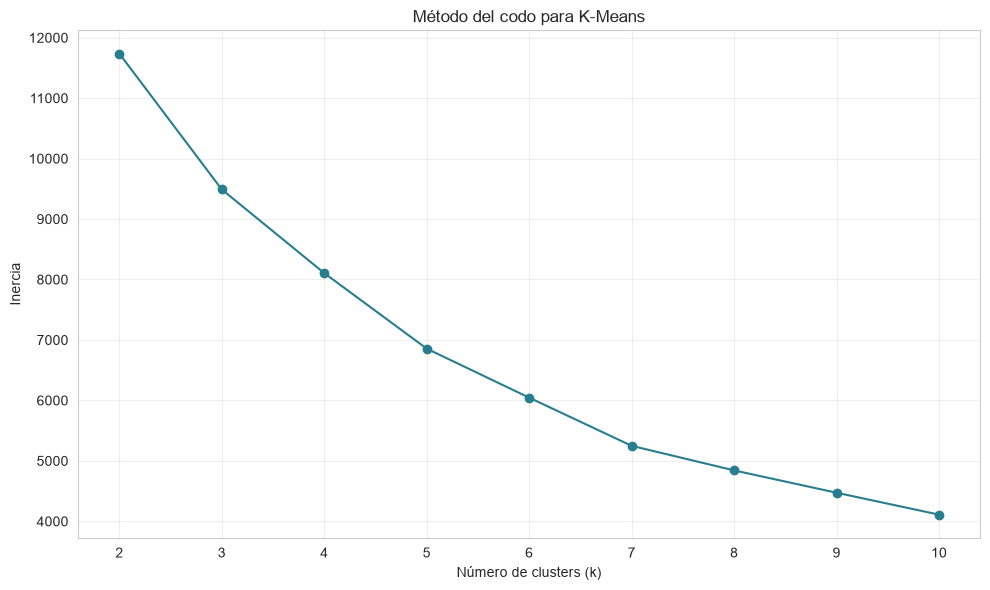

Gráfico guardado en: reports\figures\codo_kmeans.png


In [4]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    modelo.fit(X_scaled)
    inertias.append(modelo.inertia_)

figura, eje = plt.subplots()
eje.plot(list(k_values), inertias, marker="o", color="#287d8e")
eje.set_title("Método del codo para K-Means")
eje.set_xlabel("Número de clusters (k)")
eje.set_ylabel("Inercia")
eje.set_xticks(list(k_values))
eje.grid(alpha=0.3)
figura.tight_layout()

elbow_path = FIGURES_DIR / "codo_kmeans.png"
figura.savefig(elbow_path, dpi=120)
plt.show()
plt.close(figura)
print(f"Gráfico guardado en: {elbow_path.relative_to(PROJECT_ROOT)}")

## Paso 4: entrenar K-Means con el k elegido

La curva no muestra un codo perfecto, pero empieza a aplanarse aproximadamente entre `k=5` y `k=6`. Usaremos `k=5` como eleccion inicial para esta ejecucion. Es una decision razonada, no una verdad unica: compara otros valores y observa como cambian Silhouette, Davies–Bouldin y la utilidad de los grupos.

> **Silhouette:** compara qué tan cerca está un punto de su propio cluster frente a otros. Va de `-1` a `1`; valores altos suelen indicar clusters más separados.
>
> **Davies–Bouldin:** compara dispersión interna con separación entre grupos. Valores bajos suelen indicar clusters más compactos y separados.

In [5]:
K_OPTIMO = 5  # La curva empieza a aplanarse aproximadamente entre k=5 y k=6.
kmeans_model = KMeans(
    n_clusters=K_OPTIMO,
    random_state=RANDOM_STATE,
    n_init=10,
)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_davies_bouldin = davies_bouldin_score(X_scaled, kmeans_labels)

print(f"Clusters encontrados: {len(np.unique(kmeans_labels))}")
print(f"Silhouette: {kmeans_silhouette:.4f} (mayor suele ser mejor)")
print(f"Davies-Bouldin: {kmeans_davies_bouldin:.4f} (menor suele ser mejor)")

kmeans_path = MODELS_DIR / "kmeans.pkl"
joblib.dump(kmeans_model, kmeans_path)
print(f"Modelo guardado en: {kmeans_path.relative_to(PROJECT_ROOT)}")

Clusters encontrados: 5
Silhouette: 0.2925 (mayor suele ser mejor)
Davies-Bouldin: 1.2803 (menor suele ser mejor)
Modelo guardado en: models\kmeans.pkl


## Paso 5: DBSCAN — agrupamiento por densidad

DBSCAN no necesita que indiquemos `k`. Usa dos parámetros: `eps`, el radio que define qué tan cerca deben estar dos puntos para ser vecinos, y `min_samples`, el mínimo de puntos en ese vecindario para considerarlo denso.

DBSCAN identifica los puntos que no pertenecen a ninguna región suficientemente densa como ruido y les asigna la etiqueta `-1`. Aquí empezamos con `eps=0.5` y `min_samples=5`. El resultado depende de la escala y de estos parámetros, así que conviene revisarlo si aparecen cero grupos, un solo grupo o casi todos los puntos como ruido.

Calcularemos Silhouette y Davies–Bouldin solo sobre los puntos no marcados como ruido, y solo si quedan al menos dos clusters; de lo contrario esas métricas no están definidas.

In [6]:
dbscan_model = DBSCAN(eps=0.5, min_samples=5, n_jobs=-1)
dbscan_labels = dbscan_model.fit_predict(X_scaled)

n_dbscan_clusters = len(set(dbscan_labels) - {-1})
dbscan_outliers_mask = dbscan_labels == -1
n_dbscan_outliers = int(dbscan_outliers_mask.sum())
dbscan_core_mask = ~dbscan_outliers_mask
valid_dbscan_labels = dbscan_labels[dbscan_core_mask]

# Las metricas internas requieren por lo menos dos clusters no vacios.
dbscan_silhouette = np.nan
dbscan_davies_bouldin = np.nan
if len(np.unique(valid_dbscan_labels)) >= 2:
    X_dbscan_core = X_scaled[dbscan_core_mask]
    dbscan_silhouette = silhouette_score(X_dbscan_core, valid_dbscan_labels)
    dbscan_davies_bouldin = davies_bouldin_score(X_dbscan_core, valid_dbscan_labels)

print(f"Clusters encontrados (sin contar ruido): {n_dbscan_clusters}")
print(f"Puntos atipicos / ruido: {n_dbscan_outliers} de {len(X_scaled)}")
print(f"Silhouette sin ruido: {dbscan_silhouette:.4f}")
print(f"Davies-Bouldin sin ruido: {dbscan_davies_bouldin:.4f}")

# sklearn.DBSCAN no implementa predict; guardamos el resultado del ajuste.
dbscan_path = MODELS_DIR / "dbscan.pkl"
joblib.dump(dbscan_model, dbscan_path)
print(f"Modelo guardado en: {dbscan_path.relative_to(PROJECT_ROOT)}")

Clusters encontrados (sin contar ruido): 45
Puntos atipicos / ruido: 978 de 2200
Silhouette sin ruido: 0.3287
Davies-Bouldin sin ruido: 0.9697
Modelo guardado en: models\dbscan.pkl


## Paso 6: comparar K-Means y DBSCAN

K-Means suele ser sencillo y rápido una vez elegido `k`, pero necesita que indiquemos cuántos grupos formar y funciona mejor con grupos compactos. DBSCAN no requiere `k`, puede encontrar formas más variadas y marca ruido; a cambio, es sensible a `eps` y `min_samples`.

**¿Cuál usar?** Si tenemos una idea de cuántos grupos buscamos y queremos asignar nuevos puntos, K-Means puede ser una buena base. Si esperamos ruido y grupos definidos por densidad, DBSCAN puede ser más apropiado. La decisión depende de los datos y del uso posterior.

In [7]:
metricas_clustering = pd.DataFrame(
    [
        {
            "modelo": "K-Means",
            "n_clusters": len(np.unique(kmeans_labels)),
            "silhouette": kmeans_silhouette,
            "davies_bouldin": kmeans_davies_bouldin,
            "n_outliers": 0,
        },
        {
            "modelo": "DBSCAN",
            "n_clusters": n_dbscan_clusters,
            "silhouette": dbscan_silhouette,
            "davies_bouldin": dbscan_davies_bouldin,
            "n_outliers": n_dbscan_outliers,
        },
    ]
)

display(metricas_clustering.round(4))
comparison_path = REPORTS_DIR / "comparacion_clustering.csv"
metricas_clustering.to_csv(comparison_path, index=False)
print(f"Comparacion guardada en: {comparison_path.relative_to(PROJECT_ROOT)}")

,modelo,n_clusters,silhouette,davies_bouldin,n_outliers
0,K-Means,5,0.2925,1.2803,0
1,DBSCAN,45,0.3287,0.9697,978


Comparacion guardada en: reports\comparacion_clustering.csv


## Paso 7: PCA — reducción dimensional

PCA transforma las variables en componentes que son combinaciones lineales de las features originales, ordenadas por la cantidad de varianza que explican. Reducir de siete variables a dos permite hacer una visualización 2D y observar una proyección de los datos.

La proyección pierde información: dos componentes no necesariamente conservan toda la estructura. Colorearemos cada punto con el cluster de K-Means para explorar cómo se distribuyen los grupos en este plano.

Varianza explicada por componente: 27.59%, 18.48%
Varianza explicada acumulada: 46.07%


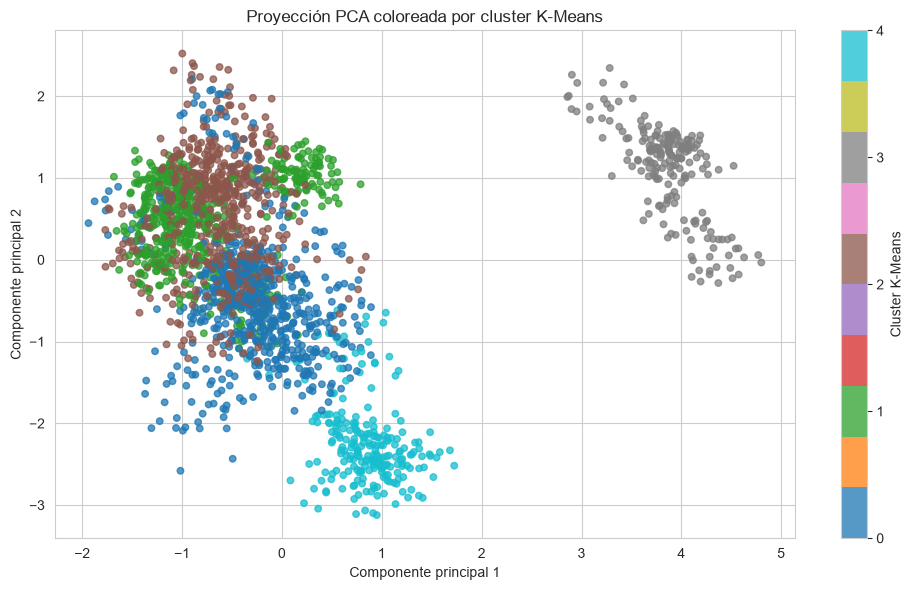

Gráfico guardado en: reports\figures\pca_kmeans.png


In [8]:
pca_model = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_model.fit_transform(X_scaled)

print(
    "Varianza explicada por componente: "
    f"{pca_model.explained_variance_ratio_[0]:.2%}, "
    f"{pca_model.explained_variance_ratio_[1]:.2%}"
)
print(f"Varianza explicada acumulada: {pca_model.explained_variance_ratio_.sum():.2%}")

figura, eje = plt.subplots()
scatter = eje.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    s=22,
    alpha=0.75,
)
eje.set_title("Proyección PCA coloreada por cluster K-Means")
eje.set_xlabel("Componente principal 1")
eje.set_ylabel("Componente principal 2")
barra = figura.colorbar(scatter, ax=eje, ticks=np.unique(kmeans_labels))
barra.set_label("Cluster K-Means")
figura.tight_layout()

pca_path = FIGURES_DIR / "pca_kmeans.png"
figura.savefig(pca_path, dpi=120)
plt.show()
plt.close(figura)
print(f"Gráfico guardado en: {pca_path.relative_to(PROJECT_ROOT)}")

## Paso 8: t-SNE — visualización no lineal

t-SNE crea una proyección de baja dimensión que intenta conservar vecindades locales: puntos cercanos en el espacio original tienden a quedar cerca en el mapa 2D. A diferencia de PCA, puede representar relaciones no lineales y ayudar a explorar estructuras complejas.

La distancia entre grupos en el gráfico no debe interpretarse como una medida exacta de separación global. t-SNE es principalmente una herramienta de visualización; su resultado depende de parámetros y de la inicialización.

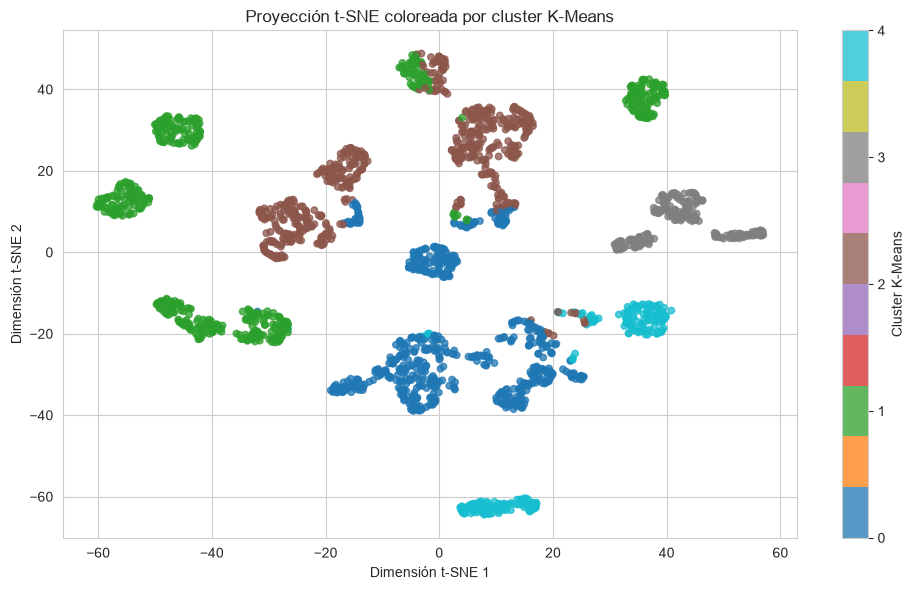

Gráfico guardado en: reports\figures\tsne_kmeans.png


In [9]:
tsne_model = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto",
    perplexity=30,
)
X_tsne = tsne_model.fit_transform(X_scaled)

figura, eje = plt.subplots()
scatter = eje.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    s=22,
    alpha=0.75,
)
eje.set_title("Proyección t-SNE coloreada por cluster K-Means")
eje.set_xlabel("Dimensión t-SNE 1")
eje.set_ylabel("Dimensión t-SNE 2")
barra = figura.colorbar(scatter, ax=eje, ticks=np.unique(kmeans_labels))
barra.set_label("Cluster K-Means")
figura.tight_layout()

tsne_path = FIGURES_DIR / "tsne_kmeans.png"
figura.savefig(tsne_path, dpi=120)
plt.show()
plt.close(figura)
print(f"Gráfico guardado en: {tsne_path.relative_to(PROJECT_ROOT)}")

## Paso 9: comparar PCA y t-SNE

- **PCA** es una transformación lineal y rápida; sus componentes resumen varianza global y también pueden servir como features para otros modelos.
- **t-SNE** suele ser más costoso y se centra en conservar vecindades locales. Es útil para visualización exploratoria, pero no conviene interpretar sus ejes como variables ni como coordenadas de negocio.

**¿Cuál usar?** PCA para reducción dimensional reproducible y como posible paso previo de un pipeline; t-SNE para explorar visualmente estructuras locales complejas. Ambos gráficos son proyecciones: no sustituyen la evaluación de los clusters en el espacio original.

Para el benchmark, K-Means tiene `predict`. DBSCAN de scikit-learn no lo implementa: construiremos una asignación aproximada al cluster del punto núcleo más cercano dentro de `eps`. Esa consulta no equivale a volver a ejecutar DBSCAN sobre un conjunto nuevo.

In [10]:
loaded_scaler = joblib.load(MODELS_DIR / "scaler_clustering.pkl")
loaded_kmeans = joblib.load(MODELS_DIR / "kmeans.pkl")
loaded_dbscan = joblib.load(MODELS_DIR / "dbscan.pkl")

# Se consultan 100 observaciones una a una y se promedia la latencia por punto.
benchmark_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X), size=100, replace=False
)
benchmark_raw = X.iloc[benchmark_indices]
benchmark_scaled = loaded_scaler.transform(benchmark_raw)

kmeans_latencies_ms = []
for sample in benchmark_scaled:
    start = time.perf_counter_ns()
    loaded_kmeans.predict(sample.reshape(1, -1))
    kmeans_latencies_ms.append((time.perf_counter_ns() - start) / 1_000_000)

core_points = loaded_dbscan.components_
core_labels = loaded_dbscan.labels_[loaded_dbscan.core_sample_indices_]
dbscan_neighbor_index = None
if len(core_points) > 0:
    dbscan_neighbor_index = NearestNeighbors(radius=loaded_dbscan.eps)
    dbscan_neighbor_index.fit(core_points)


def predecir_dbscan_aproximado(sample_scaled):
    """Asigna un punto al cluster de su punto núcleo más cercano dentro de eps.

    Es una extensión práctica para medir consultas; DBSCAN estándar no ofrece
    predicción inductiva y esta regla no sustituye a reajustar el clustering.
    """
    if dbscan_neighbor_index is None:
        return -1

    distances, indices = dbscan_neighbor_index.radius_neighbors(
        sample_scaled.reshape(1, -1),
        return_distance=True,
        sort_results=True,
    )
    if len(indices[0]) == 0:
        return -1
    nearest_core_index = indices[0][np.argmin(distances[0])]
    return int(core_labels[nearest_core_index])


dbscan_latencies_ms = []
for sample in benchmark_scaled:
    start = time.perf_counter_ns()
    predecir_dbscan_aproximado(sample)
    dbscan_latencies_ms.append((time.perf_counter_ns() - start) / 1_000_000)

benchmark_results = {
    "n_consultas": 100,
    "kmeans_latencia_promedio_ms": float(np.mean(kmeans_latencies_ms)),
    "dbscan_aproximado_latencia_promedio_ms": float(np.mean(dbscan_latencies_ms)),
    "nota_dbscan": (
        "Estimacion por vecino nucleo dentro de eps; DBSCAN de scikit-learn "
        "no implementa predict."
    ),
}

benchmark_path = REPORTS_DIR / "benchmark_latency.json"
with benchmark_path.open("w", encoding="utf-8") as archivo:
    json.dump(benchmark_results, archivo, indent=2, ensure_ascii=False)

display(pd.DataFrame([benchmark_results]))
print(f"Benchmark guardado en: {benchmark_path.relative_to(PROJECT_ROOT)}")
print("Clase 5 completada. Revisa reports/ y models/.")

,n_consultas,kmeans_latencia_promedio_ms,dbscan_aproximado_latencia_promedio_ms,nota_dbscan
0,100,0.204846,0.507782,Estimacion por vecino nucleo dentro de eps; DB...


Benchmark guardado en: reports\benchmark_latency.json
Clase 5 completada. Revisa reports/ y models/.


## Conclusiones de la clase

1. **K-Means** es rápido, pero requiere elegir `k` y funciona mejor con grupos relativamente compactos.
2. **DBSCAN** puede detectar puntos atípicos sin indicar `k`, pero es sensible a `eps` y `min_samples`.
3. **PCA** es útil para reducir dimensiones de forma lineal y visualizar parte de la varianza.
4. **t-SNE** ayuda a explorar vecindades y estructuras locales complejas, pero no conserva fielmente distancias globales.
5. **Silhouette** y **Davies–Bouldin** permiten evaluar aspectos distintos del agrupamiento; hay que interpretarlas junto con los datos y el objetivo.

### Conexión con Práctica 1

En APE 7–8 van a aplicar este flujo a Wall-Following: K-Means, DBSCAN, Silhouette, PCA, t-SNE y benchmarking. Cambiará el dataset, pero se mantienen las preguntas y el proceso de análisis.

### Próxima clase

**Clase 6:** integración, benchmarking y cierre del Bloque 1.